## **一、S5-02｜把图文 Token 接到同一条速度主干**

你已经在 S4-02 走过了完整链路：图像变成潜变量，加噪以后由带文本条件的 DiT 预测速度，最后用 ODE 采样和 VAE 解码。S5-01 则把一个局部问题拆开了：图文 Token 进入同一次注意力时，哪些位置可见，图像的二维坐标怎样进入注意力？这节把那两个机制接回可训练的生成主干。

我们用配对实验比较两套教学配置。Plain DiT 由图像查询读取冻结文本；Single-Stream 则持续更新图文状态。两组对齐编码器、速度目标、训练样本、每一步的随机输入和采样预算；位置编码、宽度和头数也随配置一起变化。最后分开回答三个问题：**前向与梯度接对了吗？模型使用了条件吗？在这次小实验里采样表现如何？**

[上一条训练链路](S4_02_LatentFlow与PlainDiT训练闭环.ipynb) · [联合注意力与 2D RoPE](S5_01_JointAttention与2DRoPE.ipynb) · [MiniGen2 学习目录](../MiniGen2学习目录.md)

### **1. 本课用什么数据和组件**

复用 S4-02 的合成教学图：红、蓝两种颜色与圆、方两种形状交叉得到四类。训练 64 张，留出 32 张，同一四类内换位置和尺寸。冻结本地 SDXL VAE 与 CLIP 文本塔，训练只更新速度主干。编码使用 VAE 后验均值乘组件配置的缩放系数，解码做逆缩放。CLIP 特征、布尔掩码、潜变量和训练模型都放在当前内核内存。

代码按标签和源码 SHA-256 读取前课指定教学单元。它重建本课所需的玩具数据和冻结特征，只载入旧采样器和解析器的定义，并复用 S5-01 的图像坐标与旋转函数。第一处图像展示的是输入样本与 **VAE 重建**。后面才展示本课从高斯噪声采出的图像。

| 路径 | 输入尺寸 | 本课用途 |
| --- | --- | --- |
| 教学短训与采样 | 64×64，潜变量 4×8×8 | 比较学习链路、条件干预和简单属性命中 |
| 分辨率冒烟 | 256×256，潜变量 4×32×32 | 检查完整文本槽位与更长图像序列的前向 |
| v2 正式 B0/B1/B2 | 256×256 OpenClipart | 在后续工程阶段独立训练和验收 |

前置条件是 MiniGen 的 Notebook 环境、前课中记录的本地冻结资产及未变更的参考单元。冻结组件按前课约定离线加载。若参考单元源码变更，身份检查会报出来源和标签，方便显式复核依赖。

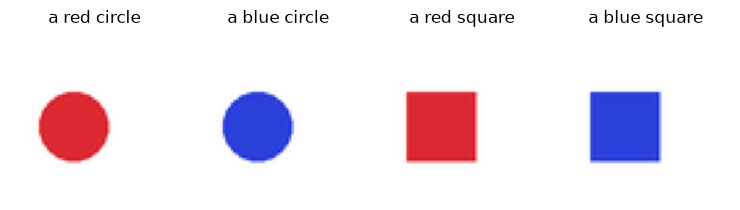

Python 3.12.14 | PyTorch 2.14.1 | CPU FP32
train=64 | val=32 | shared image hashes=0


/Users/lucius/projects/personal/MiniGen/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1107 15:22:22.660000 71096 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 196/196 [00:00<00:00, 43489.58it/s]

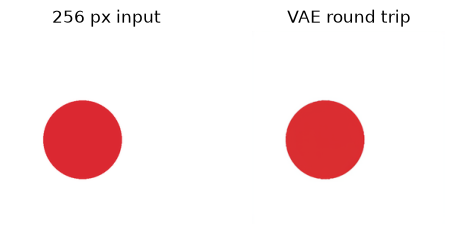

VAE revision=207b116dae70ace3637169f1ddd2434b91b3a8cd | scale=0.13025
CLIP revision=3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268 | valid tokens=[5, 5, 5, 5, 2]
256 latent=(1, 4, 32, 32); train latent=(64, 4, 8, 8)
text (5, 77, 512) -> (5, 5, 512); cache in RAM
train latent mean=0.2855 std=1.4042
components + cache: 5.67 s
256 probe patch tensor (1, 256, 16)
trainable DiT params = 609,714


In [1]:
import ast
import hashlib
import math
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import torch
from torch import Tensor, nn
from torch.nn import functional as F

root = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "configs/models/sdxl_vae.json").is_file()
)
s4 = "S4_02_LatentFlow与PlainDiT训练闭环.ipynb"
s5 = "S5_01_JointAttention与2DRoPE.ipynb"


def load_lesson_cell(
    filename: str,
    tag: str,
    digest: str,
    namespace: dict,
    only: tuple[str, ...] = (),
) -> None:
    """在内存执行唯一且哈希一致的旧教学单元，或仅载入其中指定的函数定义。"""
    notebook = nbformat.read(root / "docs/learning" / filename, as_version=4)
    matches = [
        c.source
        for c in notebook.cells
        if c.cell_type == "code" and tag in c.metadata.get("tags", ())
    ]
    if len(matches) != 1 or hashlib.sha256(matches[0].encode()).hexdigest() != digest:
        raise ValueError(f"source identity mismatch: {filename}:{tag}")
    tree = ast.parse(matches[0])
    if only:
        tree.body = [
            node for node in tree.body if isinstance(node, ast.FunctionDef) and node.name in only
        ]
        if {node.name for node in tree.body} != set(only):
            raise ValueError(f"source definitions missing: {only}")
    exec(compile(tree, f"{filename}:{tag}", "exec"), namespace)


prev = {}
load_lesson_cell(
    s4, "data", "04f2cdfea619c9454ba0cb8d05f0909816f80eaa683f15f051d15ad166d0b354", prev
)
load_lesson_cell(
    s4, "components", "128375f1a51d7004775ea3efdfdb37d74a4679d25a8d9fdabc7b7df6c07e58c6", prev
)
load_lesson_cell(
    s4, "architecture", "ad713285c3f4dfb6c96d675cd66cbfc27a6bc554847376354a87f9fe381af583", prev
)
load_lesson_cell(
    s4,
    "sampler",
    "a40a5b6daae22c361a48305e6529675d6fef34aa7df2a5584d753384230d35ae",
    prev,
    ("sample_reference",),
)
load_lesson_cell(
    s4,
    "samples",
    "4fac03aef4d90db8a1cd935bc0155d44c570f6dea1b2adb7b454d27facb174a6",
    prev,
    ("classify_icon", "report_scores"),
)
rope_env = {"torch": torch, "Tensor": Tensor, "math": math}
load_lesson_cell(
    s5,
    "rope",
    "bfc98cf52bc04ea35123690c2798a98aa45df80552d2850c911382dec4b132e9",
    rope_env,
    ("grid_coords", "rotate_2d"),
)
grid_coords, rotate_2d = rope_env["grid_coords"], rope_env["rotate_2d"]
base_defs = prev["reference_namespace"]
patchify = prev["patchify"]
unpatchify = prev["unpatchify"]
sincos_1d = base_defs["sincos_1d"]
Plain = prev["ReferenceDiT"]
vae, captions = prev["vae"], prev["captions"]
train_z, train_y = prev["train_z"], prev["train_y"]
val_z, val_y = prev["val_z"], prev["val_y"]
text_bank, mask_bank = prev["text_bank"], prev["mask_bank"]

## **二、Plain 与 Single-Stream 的计算图**

### **1. 文本在主干里发生了什么**

设 $I^{(\ell)}$ 为第 $\ell$ 层的图像 Token，$C$ 为冻结编码器的输出。Plain 先用图像自注意力和 MLP 更新图像，再用图像 Q 读取该层从 $C$ 投影出的文本 K/V。交叉注意力只为图像查询返回更新，每层文本投影可以不同，但它们读取同一份 $C$。

Single-Stream 先把文本映射到主干宽度得到 $T^{(0)}$，再让 $[T^{(\ell)};I^{(\ell)}]$ 一起经历共享的自注意力和 MLP。教学版允许有效文本与图像在同一层双向交互。第 $\ell+1$ 层读取的文本状态因此可能已经吸收图像信息。这些 **主干内的文本状态** 会变，冻结 CLIP 的输出 $C$ 仍可预先计算。

| 位置 | Plain 教学对照 | Single-Stream 教学参考 |
| --- | --- | --- |
| 输入 | 图像 patch 投影；文本进入各层 Cross-Attention | 图像与文本各自投影，加模态向量后拼接 |
| 重复 Block | 图像自注意力 → 图像 MLP → 文本交叉注意力 | 同一个 QKV、输出投影和 MLP 处理拼接序列 |
| 下一层的文本 | 同一份冻结特征 $C$ | 上一层更新后的文本 Token |
| 位置 | 图像加二维绝对正弦位置编码 | 图像 Q/K 使用二维 RoPE |
| 输出 | 图像潜变量速度 | 裁出图像后缀，恢复相同形状的速度 |

如果只数每头的稠密注意力打分位置，Plain 每层合计 $n_i^2+n_i n_t$，Single-Stream 为 $(n_t+n_i)^2$。以 256px 冒烟为例，$n_i=256$、$n_t=77$，每头分别有 85,248 与 110,889 个打分位置。以短训的 16 个图像 patch 和 5 个文本槽位为例，分别为 336 与 441。这里按 **槽位** 计数，布尔掩码定义语义可见性。实际 FLOPs 与延迟还受头数、投影、MLP、内核和批大小影响。

### **2. Qwen-Image-2.1｜从发布配置到一次前向**

从「给参考图换一种背景」出发：模型要同时看懂图和修改指令，又要在许多去噪步里反复更新目标。先看一条输入怎样排进主干，再用掩码和时间条件解释，哪些计算可以留到下一步复用。下文按 2026 年 11 月 7 日可核对的公开配置与推理代码讲解。

#### **i. 先分清哪一代模型、哪份资料**

Qwen-Image-2.1 把文本与图像潜变量送进同一条生成主干。Qwen 团队 2025 年的《Qwen-Image Technical Report》第 2.4 节描述的是初代 Qwen-Image：图文分支采用 MMDiT，正文介绍其图文两路，图 8 对照图文位置策略，表 1 给出 60 层配置，生成主干约 20B 参数。DiT 原论文第 3.1 节和图 3 可以用来复习 patch 与时间调制，SD3 论文第 4 节和图 2(b) 可以用来对照两路怎样共享注意力。2.1 的层数、单流 Block、掩码和缓存，下文依据 **2.1 的发布材料与推理实现**。 [DiT 论文](https://arxiv.org/abs/2212.09748v2) · [SD3 第 4 节](https://arxiv.org/html/2403.03206v1#S4) · [初代 Qwen-Image 第 2.4 节](https://arxiv.org/html/2508.02324v1#S2.SS4) · [2.1 官方架构说明](https://github.com/QwenLM/Qwen-Image-2.1#architecture)

| 核对项 | Qwen-Image-2.1 发布配置 | 本课 Single-Stream |
| --- | --- | --- |
| 条件编码 | Qwen3-VL-8B，接到 DiT 的特征宽度是 4096 | CLIP 文本塔，特征宽度 512 |
| 图像表示 | RGBA VAE，空间每轴压缩 16 倍，潜变量 64 通道 | SDXL VAE，空间每轴压缩 8 倍，潜变量 4 通道 |
| 图像 token | 潜网格 1×1 patch，每个格点产生一个 token | 潜网格 2×2 patch，每个 token 展平为 16 个数 |
| 生成主干 | 约 7B，32 个 Block，32 头，每头 128 维，宽度 $32\times128=4096$ | 短训配置为 2 个 Block，5 头，每头 24 维，宽度 120 |
| 可见性与位置 | 分块因果；联合序列三轴 RoPE，每头分配 16/56/56 维 | 有效 token 双向；只有图像 Q/K 做二维 RoPE |
| 时间调制 | 全主干共用四组参数，分开计算前缀与目标 | 每个 Block 独立产生六组参数，图文共用当前时间 |

表中的 7B 指视觉生成主干，条件编码器有自己的参数。以 1024×1024 输出为例，潜网格是 64×64，DiT 收到 4096 个目标图像 token，每个投影前有 64 个潜通道。分辨率改为 2048×2048，目标 token 增至 16384。计算联合序列长度还要加上文本和参考图；这比只拿像素高宽估注意力规模更直接。 [官方模型卡](https://huggingface.co/Qwen/Qwen-Image-2.1) · [Transformer 发布配置](https://huggingface.co/Qwen/Qwen-Image-2.1/blob/main/transformer/config.json) · [VAE 发布配置](https://huggingface.co/Qwen/Qwen-Image-2.1/blob/main/vae/config.json)

#### **ii. 先追一遍编辑时图文如何排列**

1. **准备条件前缀。** Qwen3-VL 根据对话模板编码提示词和参考图；参考图还要走 VAE，得到另一份潜变量。VLM 提供上下文化条件特征，VAE 提供 DiT 要处理的图像潜变量。
2. **替换占位，再追加目标。** 管线依据参考图的网格，把 VLM 序列里的图像占位扩到 VAE token 数。DiT 在对应位置填入参考图的 VAE token，保留其余条件特征。参考图保留在前缀里的原有位置；目标图从高斯噪声初始化，放在整个前缀末尾。纯文生图没有参考图占位。编辑的一条简化序列可以是 `[前段文本, 参考图块, 后段文本, 目标图块]`。
3. **每步只更新目标潜变量。** 管线截取 Transformer 输出末尾的目标区间，再交给 `FlowMatchEulerDiscreteScheduler` 更新。最后把 token 还原成潜网格，按 VAE 配置恢复每通道的均值和标准差，再解码。发布实现把这次模型输出命名为 `noise_pred`，实际步进应看调用的 Flow scheduler。 [组件清单](https://huggingface.co/Qwen/Qwen-Image-2.1/blob/main/model_index.json) · [推理管线](https://github.com/huggingface/diffusers/blob/6256aa7/src/diffusers/pipelines/qwenimage21/pipeline_qwenimage21.py)

#### **iii. 从六个 token 算清分块因果与三轴 RoPE**

设 $i$ 是 query 的序列位置，$j$ 是 key 的位置，$B(i)$ 为其图像块编号，文本没有图像块编号。可见条件是：

$$\operatorname{allow}(i,j)=\operatorname{valid}(j)\land\big[(j\le i)\lor(i,j\text{ 都是图像 token 且 }B(i)=B(j))\big].$$

令 $T_0,T_1$ 为图前和图后文字，$R_0,R_1$ 属于同一参考图，$G_0,G_1$ 属于同一目标图。所有键有效时，按 $[T_0,R_0,R_1,T_1,G_0,G_1]$ 排列，得到：

| query ↓ / key → | $T_0$ | $R_0$ | $R_1$ | $T_1$ | $G_0$ | $G_1$ |
| --- | --- | --- | --- | --- | --- | --- |
| $T_0$ | 1 | 0 | 0 | 0 | 0 | 0 |
| $R_0$ | 1 | 1 | 1 | 0 | 0 | 0 |
| $R_1$ | 1 | 1 | 1 | 0 | 0 | 0 |
| $T_1$ | 1 | 1 | 1 | 1 | 0 | 0 |
| $G_0$ | 1 | 1 | 1 | 1 | 1 | 1 |
| $G_1$ | 1 | 1 | 1 | 1 | 1 | 1 |

$R_0$ 能读到序列中靠后的 $R_1$，因为它们同属一张图；它不能读 $G_0$。$T_1$ 能读取先出现的参考图，前缀的所有行都看不到目标图。这个规则同时保留图像块内的双向空间交互和前缀的步间独立性。S5-01 的两块示意让文本块内部也双向，两个掩码不能直接互换。

掩码回答 **能看谁**；RoPE 回答 **打分如何受位置影响**。发布实现给每头分出帧位、高度、宽度三组。文本位置沿三轴一起递增；同一图像块的帧位保持固定，高宽轴换成各自居中的网格坐标。对于上表的序列，若两张图都简化为 1×2 网格，$T_0$ 的三轴坐标是 $(0,0,0)$，两个参考图 token 分别是 $(1,-1,-1)$、$(1,-1,0)$。参考块过后，位置游标前进 $\max(1,2)=2$，所以 $T_1$ 为 $(3,3,3)$，后面的目标块从帧位 4 开始。同图 token 的帧位差为零，图内相对位移由高宽两轴给出。 [分块因果规则](https://github.com/QwenLM/Qwen-Image-2.1#architecture) · [Transformer 中的掩码和三轴 RoPE](https://github.com/huggingface/diffusers/blob/main/src/diffusers/models/transformers/transformer_qwenimage21.py)

#### **iv. 顺着一次 Block 前向，找共享调制和串行残差**

把投影并排好的图文状态记为 $X$。发布实现的时间嵌入经过一个主干级共享的 `SiLU → Linear(d,4d)`，生成注意力和 MLP 各一组缩放与门控。所有 Block 接收同一组调制结果，Block 各自保有注意力和 MLP 权重。设 $s_a,s_m$ 是缩放量，$g_a,g_m$ 是门的原值，则前向可写成：

$$X'=X+\tanh(g_a)\odot\operatorname{Attn}\big(\operatorname{LN}_1(X)\odot(1+s_a)\big).$$

$$X''=X'+\tanh(g_m)\odot\operatorname{SwiGLU}\big(\operatorname{LN}_2(X')\odot(1+s_m)\big).$$

这里的 SwiGLU 代表完整前馈分支，内部宽度为 $3d$。注意力投影后先做逐头 Q/K RMSNorm，再加三轴 RoPE，然后按分块掩码打分。调制不含额外的平移向量；MLP 读的是注意力写回后的 $X'$。本课下面的 Block 为每层生成六组调制，含平移，MLP 用 GELU。S6-01 的混元式合流块还会把注意力和 MLP 改为读取同一个归一化输入，两个方向的“单流”要分开看。 [Diffusers 2.1 接入变更](https://github.com/huggingface/diffusers/pull/14804/files) · [Transformer 实现](https://github.com/huggingface/diffusers/blob/main/src/diffusers/models/transformers/transformer_qwenimage21.py)

#### **v. 为什么缓存成立，哪些变化会让它失效**

发布配置启用 `causal_condition`。前缀（文本和参考图）使用固定的时间条件 0，目标图使用当前去噪步的时间。时间 0 在这里描述 **送给前缀的固定调制输入**，不表示把 MiniGen 的时间方向照搬到 Qwen。

可以按层验证。输入层的前缀特征和位置固定；若第 $\ell$ 层的前缀状态固定，那么前缀 query 只读固定的前缀 K/V，调制与权重也固定，输出到第 $\ell+1$ 层的前缀依然固定。由此，每层前缀的 K/V 都能复用。第一次前向走 `extract`，保存各层的前缀 K/V；后续 `cached` 只重新计算目标行，用缓存的前缀 K/V 和本步目标 K/V 做注意力。位置、可见性、前缀条件或分支变了就要重新核对缓存；启用真实 CFG 时，发布管线给正、负条件各建一份缓存。理论上的同一计算关系也不保证低精度下逐位相同，发布管线明确区分了这一点。 [发布管线的缓存与采样循环](https://github.com/huggingface/diffusers/blob/6256aa7/src/diffusers/pipelines/qwenimage21/pipeline_qwenimage21.py#L683-L738)

本课缓存的是冻结 CLIP 的输出 $C$。主干内的文本行既能读目标图，也使用当前时间，两个条件都可能随去噪步改变。因此缓存 $C$ 合理，跨步沿用文本的主干 K/V 则一般会改变结果。把缓存放在哪一层，取决于要复用的张量是否仍是同一个函数值。

| 想复核的问题 | 推荐阅读位置 |
| --- | --- |
| 参考图为什么编码两次，目标 token 从哪来？ | 管线 `_get_qwen_prompt_embeds`、`prepare_latents`、`__call__` |
| 位置怎样分轴，哪个 token 能读哪一行？ | 主干 `QwenImage21Rope`、`build_qwenimage21_block_causal_mask` |
| 一次 Block 如何使用共享调制？ | 主干 `QwenImage21TransformerBlock.forward`，再到外层 `forward` 找调制与缓存分支 |

## **三、一次完整前向｜从 latent 到图像速度**

### **1. 从空间网格排出一条序列**

令潜变量形状为 `[b,c,h,w]`，每个 patch 覆盖 $p\times p$ 个格点。沿 patch 行列按行优先排列，有 $n_i=(h/p)(w/p)$ 个 Token，每个 patch 展平成 $c p^2$ 个数。图像和文本分别线性投影到宽度 $d$，加上可学习的图像、文本模态向量，再沿序列轴拼接。

| 张量 | 256px 前向 | 64px 教学训练 |
| --- | --- | --- |
| 潜变量 | `[b,4,32,32]` | `[b,4,8,8]` |
| 展平 patch，$p=2$ | `[b,256,16]` | `[b,16,16]` |
| CLIP 文本特征 | `[b,77,512]` | `[b,5,512]` |
| 拼接 Token，$d=120$ | `[b,333,120]` | `[b,21,120]` |
| 各自的 Q、K、V，5 个头 | `[b,5,333,24]` | `[b,5,21,24]` |
| 只裁图像，投影并还原 | `[b,4,32,32]` | `[b,4,8,8]` |

训练的五个文本槽位覆盖这四条短提示的全部有效 Token，外加必要的 padding。256px 形状检查保留 CLIP 的完整 77 个槽位。以 4×4 教学 patch 网格为例，序号 6 对应行 1、列 2，因为 $6=1\times4+2$。图像区间坐标因此从 $(0,0)$ 起重新生成，与文本前缀长度无关。

### **2. 共享 Block 的六个时间调制向量**

把连续时间 $t$ 映射为 $1000t$ 后送入正弦特征和时间 MLP。这里的乘法只控制模型看到的特征刻度，ODE 仍在 $[0,1]$ 上积分。每个 Block 对时间向量先应用 SiLU，再用各自的线性层产生六组长度 $d$ 的参数，分别给注意力和 MLP 提供平移 $s$、缩放 $\gamma$ 和残差门 $g$。LayerNorm 沿最后的特征轴，参数广播到同一例的所有 Token：

$$M(X;s,\gamma)=\operatorname{LN}(X)\odot(1+\gamma)+s.$$

$$X'=X+g_a\odot\operatorname{Attention}(M(X;s_a,\gamma_a)),\qquad X''=X'+g_m\odot\operatorname{MLP}(M(X';s_m,\gamma_m)).$$

例如某个归一化后的特征分量为 2，$\gamma=0.1$、$s=-0.3$，送入子层的是 $2(1+0.1)-0.3=1.9$。如果该分量的残差门为 0，子层即便给出非零值也不会写回该分量。零初始化令有效位置的 Block 初始为恒等映射；最终输出头也初始化为零，所以初始速度为零。**只看零速度头的输出，即使把注意力接错也可能通过形状检查。** 后面会打开实际梯度路径复验。

[DiT 原论文第 3.1 节与图 3](https://arxiv.org/abs/2212.09748v2) 比较了多种条件注入方法。本课沿用 adaLN-Zero 的基本思路，用逐样本时间向量调制归一化输出，并以零门初始化残差。

### **3. 让 Q/K 知道图像坐标，让键掩码挡住 padding**

Q、K、V 由共享线性层一次产生，再拆成多头。只对图像区间的 Q/K 使用 S5-01 的 2D RoPE，V 保持原值。每头宽度 24，行列各分 12 维，各自包含 6 对旋转分量。图像对图像的打分获得轴向相对位移结构；图文跨模态打分没有同一套二维相对坐标，文本仍保留来自 CLIP 的序列特征。

SDPA 的布尔掩码在本课里是 `True = 允许作为键被读取`，形状 `[b,1,1,n]`，广播到所有头和查询。padding 查询即使被计算，也在 Block 末归零，下一层仍不可作为键；所有图像键有效，因此即使人为让全部文本无效，图像查询仍有键可读。

In [2]:
class SingleStreamBlockReference(nn.Module):
    """共享 AdaLN-Zero、QKV 和 FFN；只旋转图像区间的 Q/K。"""

    def __init__(self, width: int, heads: int) -> None:
        super().__init__()
        if heads <= 0 or width <= 0 or width % (4 * heads):
            raise ValueError("each head needs a positive width divisible by 4")
        self.width, self.heads = width, heads
        self.norm_a = nn.LayerNorm(width, elementwise_affine=False, eps=1e-6)
        self.norm_m = nn.LayerNorm(width, elementwise_affine=False, eps=1e-6)
        self.modulation = nn.Sequential(nn.SiLU(), nn.Linear(width, 6 * width))
        self.qkv = nn.Linear(width, 3 * width)
        self.proj = nn.Linear(width, width)
        self.mlp = nn.Sequential(
            nn.Linear(width, 4 * width), nn.GELU(approximate="tanh"), nn.Linear(4 * width, width)
        )
        nn.init.zeros_(self.modulation[-1].weight)
        nn.init.zeros_(self.modulation[-1].bias)

    @staticmethod
    def modulate(x: Tensor, shift: Tensor, scale: Tensor) -> Tensor:
        """将每例的 shift 和 scale 广播到它的所有 token。"""
        return x * (1 + scale[:, None, :]) + shift[:, None, :]

    def forward(
        self,
        tokens: Tensor,
        time: Tensor,
        valid: Tensor,
        n_text: int,
        coords: Tensor,
    ) -> Tensor:
        b, n, d = tokens.shape
        sa, ca, ga, sm, cm, gm = self.modulation(time).chunk(6, dim=-1)
        source = self.modulate(self.norm_a(tokens), sa, ca)
        q, k, v = (
            self.qkv(source).reshape(b, n, 3, self.heads, d // self.heads).permute(2, 0, 3, 1, 4)
        )
        q = torch.cat((q[:, :, :n_text], rotate_2d(q[:, :, n_text:], coords)), dim=2)
        k = torch.cat((k[:, :, :n_text], rotate_2d(k[:, :, n_text:], coords)), dim=2)
        attended = F.scaled_dot_product_attention(
            q, k, v, attn_mask=valid[:, None, None, :], dropout_p=0.0
        )
        tokens = tokens + ga[:, None, :] * self.proj(attended.transpose(1, 2).reshape(b, n, d))
        tokens = tokens + gm[:, None, :] * self.mlp(self.modulate(self.norm_m(tokens), sm, cm))
        return tokens.masked_fill(~valid[..., None], 0.0)

### **4. 为什么输出用文本槽位数切分**

批内五个文本槽位加十六个图像 Token 时，第一个图像 Token 总在序列索引 5。即使空字符串只给两个有效特殊 Token，索引 2 至 4 仍是文本区间。若用有效数 2 做切分，三个 padding 行会被误当成图像 patch。正确做法是保存 `text.shape[1]`，仅对其后的图像 Token 做末端时间调制、速度投影和逆 patch。

In [3]:
class SingleStreamDiTReference(nn.Module):
    """教学条件速度主干；仅从图像后缀恢复 latent。"""

    block_type = SingleStreamBlockReference

    def __init__(
        self,
        width: int = 120,
        heads: int = 5,
        depth: int = 2,
        patch: int = 2,
        channels: int = 4,
        text_width: int = 512,
    ) -> None:
        super().__init__()
        self.width, self.patch, self.channels = width, patch, channels
        patch_width = patch**2 * channels
        self.image_in = nn.Linear(patch_width, width)
        self.text_in = nn.Linear(text_width, width)
        self.modality = nn.Parameter(torch.zeros(2, width))
        self.time_mlp = nn.Sequential(nn.Linear(width, width), nn.SiLU(), nn.Linear(width, width))
        self.blocks = nn.ModuleList(self.block_type(width, heads) for _ in range(depth))
        self.final_norm = nn.LayerNorm(width, elementwise_affine=False, eps=1e-6)
        self.final_mod = nn.Sequential(nn.SiLU(), nn.Linear(width, 2 * width))
        self.output = nn.Linear(width, patch_width)
        self.apply(base_defs["TeachingDiT"]._initialize_linear)
        for linear in [
            *(block.modulation[-1] for block in self.blocks),
            self.final_mod[-1],
            self.output,
        ]:
            nn.init.zeros_(linear.weight)
            nn.init.zeros_(linear.bias)

    def forward(self, z: Tensor, feature_time: Tensor, text: Tensor, text_valid: Tensor) -> Tensor:
        b, c, h, w = z.shape
        if c != self.channels or not h or not w or h % self.patch or w % self.patch:
            raise ValueError("latent must have the configured channels and divisible h,w")
        if text.ndim != 3 or text.shape[:2] != text_valid.shape or text_valid.dtype != torch.bool:
            raise ValueError("expected matching text features and boolean mask")
        if len(text) != b or feature_time.shape != (b,):
            raise ValueError("text and time batch must match latent")
        n_text = text.shape[1]
        image = self.image_in(patchify(z, self.patch)) + self.modality[1]
        caption = (self.text_in(text) + self.modality[0]).masked_fill(~text_valid[..., None], 0.0)
        valid = torch.cat((text_valid, torch.ones_like(image[..., 0], dtype=torch.bool)), dim=1)
        tokens = torch.cat((caption, image), dim=1)
        time = self.time_mlp(sincos_1d(feature_time, self.width).to(z.dtype))
        coords = grid_coords(h // self.patch, w // self.patch).to(z.device)
        for block in self.blocks:
            tokens = block(tokens, time, valid, n_text, coords)
        shift, scale = self.final_mod(time).chunk(2, dim=-1)
        image = SingleStreamBlockReference.modulate(
            self.final_norm(tokens[:, n_text:]), shift, scale
        )
        return unpatchify(self.output(image), c, h, w, self.patch)


def velocity(
    model: nn.Module,
    z: Tensor,
    time: Tensor,
    text: Tensor,
    mask: Tensor,
) -> Tensor:
    """共用 S4-02 的连续时间特征刻度，保持训练/采样约定一致。"""
    return model(z, time * 1000.0, text, mask)


def fresh_model(kind: str, seed: int, size: int = 8) -> nn.Module:
    """每个实验从随机初始化开始；两组最终 head 均为零。"""
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(seed)
        if kind == "Plain":
            return Plain(depth=2, hidden=96, heads=4, size=size, patch=2)
        return SingleStreamDiTReference()


kinds = ("Plain", "Stream")
params = {
    kind: sum(p.numel() for p in fresh_model(kind, 50200).parameters() if p.requires_grad)
    for kind in kinds
}
print("trainable params:", params)
print(f"Stream vs Plain parameter difference: {params['Stream'] / params['Plain'] - 1:+.2%}")
with torch.no_grad():
    for kind in kinds:
        shape_test = velocity(
            fresh_model(kind, 50200, size=32),
            prev["z_256"],
            torch.tensor([0.5]),
            prev["text_full"][:1],
            prev["mask_full"][:1],
        )
        assert shape_test.shape == (1, 4, 32, 32) and torch.count_nonzero(shape_test) == 0
        print(f"{kind} 256px shape smoke (zero head): {tuple(shape_test.shape)}")

trainable params: {'Plain': 609714, 'Stream': 645856}
Stream vs Plain parameter difference: +5.93%
Plain 256px shape smoke (zero head): (1, 4, 32, 32)
Stream 256px shape smoke (zero head): (1, 4, 32, 32)


## **四、Flow 速度目标和成对短训**

### **1. 两组监督信号完全对齐**

从标准高斯取样 $\epsilon$，配对同一张图像的缩放潜变量 $z$。直线路径及其速度为：

$$z_t=(1-t)\epsilon+t z,\qquad u=\frac{\mathrm d z_t}{\mathrm d t}=z-\epsilon,\qquad t\in[0,1].$$

取标量 $z=2$、$\epsilon=-1$、$t=0.25$，可得 $z_t=-0.25$ 和 $u=3$；把这个配对的直线从 $t=0.25$ 推进 $\Delta t=0.5$ 到 $t=0.75$，位置增加 $3\times0.5=1.5$。单个配对给出一条直线，模型在总体上学习的是给定当前位置、时间和可用文本时的条件平均速度。训练随机抽 $t$，用均方误差回归 $u$；推理没有成对的干净 $z$，由模型给出的场从 $t=0$ 向 $t=1$ 积分。

留出探针固定时间档位，为每个图像和档位保留同一组噪声供两种配置及不同条件比较。做条件反事实时只替换 CLIP 特征和相应掩码：正确条件、错颜色、错形状、空字符串。比较同一个 $z_t,t,u$ 的误差，可以检查主干使用文本是否有方向正确的收益。空字符串仍有有效特殊 Token，与人为全遮文本的掩码边界测试有不同含义。

均值为何是最优回归量？记 $X=(z_t,t,C)$，$m(X)=\mathbb E[u\mid X]$。对任意预测 $f(X)$，把差写成 $f(X)-u=[f(X)-m(X)]+[m(X)-u]$。给定 $X$ 时第一项固定，第二项的条件均值为零，交叉项消失：

$$\mathbb E[\lVert f(X)-u\rVert^2\mid X]=\lVert f(X)-m(X)\rVert^2+\mathbb E[\lVert u-m(X)\rVert^2\mid X].$$

第二项与预测无关，第一项在 $f(X)=m(X)$ 时为零。这个结论描述总体目标；有限模型和有限数据只能近似它。 [Flow Matching 第 3 节](https://arxiv.org/abs/2210.02747)

In [4]:
def flow_example(clean: Tensor, noise: Tensor, t: Tensor) -> tuple[Tensor, Tensor]:
    """同一线性速度目标，t=0 是噪声，t=1 是数据。"""
    return torch.lerp(noise, clean, t[:, None, None, None]), clean - noise


def step_batch(rng: torch.Generator) -> tuple[Tensor, Tensor, Tensor, Tensor]:
    """按独立训练 RNG 取一次 16 例更新；两组直接复用这批张量。"""
    idx = torch.randint(len(train_z), (16,), generator=rng)
    clean = train_z[idx]
    eps = torch.randn(clean.shape, generator=rng)
    t = torch.rand(len(idx), generator=rng)
    ids = torch.where(torch.rand(len(idx), generator=rng) < 0.1, len(captions), train_y[idx])
    x, target = flow_example(clean, eps, t)
    return x, t, ids, target


@torch.no_grad()
def validation_rows(model: nn.Module) -> np.ndarray:
    """相同留出 x,t,u，依次使用正确、错颜色、错形状和空条件。"""
    return np.array(
        [
            [
                (velocity(model, x, t, text_bank[ids], mask_bank[ids]) - u).square().mean().item()
                for ids in (val_y, val_y ^ 1, val_y ^ 2, torch.full_like(val_y, len(captions)))
            ]
            for x, t, u in probes
        ]
    )


vrng = torch.Generator().manual_seed(50205)
probes = []
for level in (0.2, 0.5, 0.8):
    t = torch.full((len(val_z),), level)
    x, u = flow_example(val_z, torch.randn(val_z.shape, generator=vrng), t)
    probes.append((x, t, u))
zero_mse = np.mean([u.square().mean().item() for _, _, u in probes])
print(f"held-out zero velocity MSE (mean of 3 times): {zero_mse:.4f}")

held-out zero velocity MSE (mean of 3 times): 3.0672


### **2. 哪些因素匹配，哪些一起改变**

| 项目 | 预设做法 |
| --- | --- |
| 训练重复 | 两个种子，各跑一组 Plain 和 Stream，从各自随机初始化起步 |
| 输入随机性 | 同一对模型每步共用 16 个样本索引、$\epsilon$、$t$ 和 10% 整条文本丢弃结果 |
| 优化 | CPU FP32，每模型 1,600 次 AdamW 更新，学习率 0.0003，权重衰减 0.01，梯度范数上限 1 |
| 监测 | 更新前与每 400 步记录留出误差，固定使用最后一步，不根据留出曲线挑最佳点 |
| 规模 | 两组均 2 层，每头 24 维，Plain 为 96 宽/4 头，Stream 为 120 宽/5 头 |
| 条件变化 | 两组共享冻结特征与目标；模型路径、位置编码、主干宽度与头数一起变化 |

两种网络都以相同数值的种子启动各自的初始化，权重形状和结构不同，不能逐项配对。匹配更新次数与数据暴露量后，仍没有匹配 FLOPs。这个对照回答的是 **两套教学配置在同一输入协议下的表现**。样本、噪声和时间三档重复提供诊断精度，32 张留出图与训练共享四种语义组合，且两个训练种子只够做小规模重复。

seed=50211 step=   0 right val Plain=3.0672 Stream=3.0672


seed=50211 step= 400 right val Plain=1.0133 Stream=1.0133


seed=50211 step= 800 right val Plain=0.9031 Stream=0.8949


seed=50211 step=1200 right val Plain=0.8847 Stream=0.8834


seed=50211 step=1600 right val Plain=0.8725 Stream=0.8525


seed=50212 step=   0 right val Plain=3.0672 Stream=3.0672


seed=50212 step= 400 right val Plain=1.0074 Stream=0.9824


seed=50212 step= 800 right val Plain=0.9125 Stream=0.8707


seed=50212 step=1200 right val Plain=0.8690 Stream=0.8641


seed=50212 step=1600 right val Plain=0.8905 Stream=0.8705


paired CPU training + evaluation took 50.8s
seed | model | right | wrong color | wrong shape | empty
50211 | Plain  | 0.87247 | 2.32815 | 0.90662 | 0.92269
50211 | Stream | 0.85246 | 1.92900 | 0.89476 | 0.93093
50212 | Plain  | 0.89049 | 2.28363 | 0.93494 | 0.96792
50212 | Stream | 0.87049 | 1.69203 | 0.90604 | 0.96027


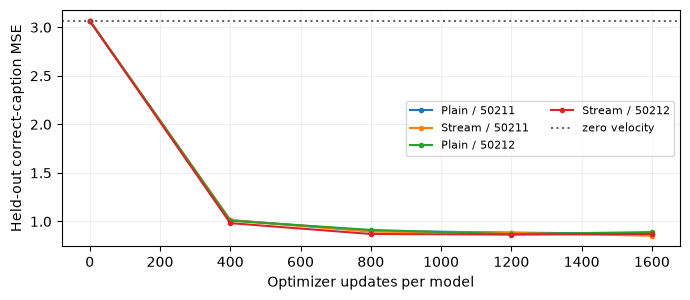

In [5]:
seeds = (50211, 50212)
checkpoints = (0, 400, 800, 1200, 1600)
trained, histories = {}, {}
started = perf_counter()
for seed in seeds:
    models = {kind: fresh_model(kind, seed) for kind in kinds}
    opts = {
        kind: torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-2)
        for kind, model in models.items()
    }
    trng = torch.Generator().manual_seed(seed + 1000)
    history = {kind: [] for kind in kinds}
    for step in range(checkpoints[-1] + 1):
        if step in checkpoints:
            for kind, model in models.items():
                history[kind].append(validation_rows(model))
            print(
                f"seed={seed} step={step:4d} right val "
                f"Plain={history['Plain'][-1][:, 0].mean():.4f} "
                f"Stream={history['Stream'][-1][:, 0].mean():.4f}",
                flush=True,
            )
        if step == checkpoints[-1]:
            break
        x, t, ids, target = step_batch(trng)
        for kind, model in models.items():
            opt = opts[kind]
            opt.zero_grad(set_to_none=True)
            loss = (velocity(model, x, t, text_bank[ids], mask_bank[ids]) - target).square().mean()
            if not torch.isfinite(loss):
                raise RuntimeError(f"{kind}: nonfinite loss")
            loss.backward()
            if step == 0:
                assert model.output.weight.grad.norm() > 0
            nn.utils.clip_grad_norm_(model.parameters(), 1.0, error_if_nonfinite=True)
            opt.step()
    for kind, model in models.items():
        trained[(seed, kind)] = model.eval()
        histories[(seed, kind)] = history[kind]
print(f"paired CPU training + evaluation took {perf_counter() - started:.1f}s")
print("seed | model | right | wrong color | wrong shape | empty")
for (seed, kind), history in histories.items():
    print(f"{seed} | {kind:6} | " + " | ".join(f"{x:.5f}" for x in history[-1].mean(0)))

fig, ax = plt.subplots(figsize=(7, 3.1))
for (seed, kind), history in histories.items():
    ax.plot(
        checkpoints, [v[:, 0].mean() for v in history], "o-", label=f"{kind} / {seed}", markersize=3
    )
ax.axhline(zero_mse, color="#666666", linestyle=":", label="zero velocity")
ax.set(xlabel="Optimizer updates per model", ylabel="Held-out correct-caption MSE")
ax.grid(alpha=0.2)
ax.legend(ncols=2, fontsize=8)
fig.tight_layout()
plt.show()

## **五、独立检查｜padding、时间、梯度与分辨率**

以下检查使用经过优化的主干，避免零头把错误掩盖。先保持有效文本、图像和时间不变，改变无效槽位的特征，再追加三个全遮槽位；输出应在浮点误差内相同。这同时检查了 **键掩码** 和 **图像后缀定位**。另外单独改变 $t$，检查输出确实依赖时间；这项干预只回答是否响应，不能证明响应量已经正确。

通过图像输入和有效文本特征反传，分别检查梯度有限且非零，无效文本特征的梯度应为零。冻结组件的参数在探针中没有梯度。最后在 256px 潜变量上对已训练的 Stream 做非零前向，检查同一主干在更长序列上能返回正确形状。这里仍用 64px 学到的权重，256px 实验只提供接口证据。

In [6]:
stream = trained[(seeds[0], "Stream")]
plain = trained[(seeds[0], "Plain")]
t0 = torch.tensor([0.2, 0.5])
batch_z, _ = flow_example(val_z[:2], torch.zeros_like(val_z[:2]), t0)
ids = torch.tensor([4, 0])
features, valid = text_bank[ids], mask_bank[ids]
edited = torch.where(valid[..., None], features, 123.0)
appended = torch.cat((features, torch.full((2, 3, features.shape[-1]), -55.0)), dim=1)
extended = torch.cat((valid, torch.zeros((2, 3), dtype=torch.bool)), dim=1)

with torch.no_grad():
    for kind, model in (("Plain", plain), ("Stream", stream)):
        initial = velocity(model, batch_z, t0, features, valid)
        changed = velocity(model, batch_z, t0, edited, valid)
        longer = velocity(model, batch_z, t0, appended, extended)
        torch.testing.assert_close(initial, changed, rtol=1e-5, atol=3e-6)
        torch.testing.assert_close(initial, longer, rtol=1e-5, atol=3e-6)
        time_probe = velocity(model, batch_z, t0 + 0.2, features, valid)
        time_rms = (initial - time_probe).square().mean().sqrt().item()
        assert time_rms > 1e-3
        pad_delta = max((initial - changed).abs().max(), (initial - longer).abs().max())
        print(f"{kind}: padding max delta={pad_delta:.3g}; t-only RMS delta={time_rms:.5f}")
    # 全屏蔽文本只是 mask 边界测试，训练空条件来自 CLIP 的 BOS/EOS。
    no_text = torch.zeros_like(valid)
    only_image = velocity(stream, batch_z, t0, features, no_text)
    assert torch.isfinite(only_image).all()
    torch.testing.assert_close(only_image, velocity(stream, batch_z, t0, -features, no_text))
    t_large = torch.tensor([0.5])
    z_large, _ = flow_example(prev["z_256"], torch.zeros_like(prev["z_256"]), t_large)
    large = velocity(stream, z_large, t_large, prev["text_full"][:1], prev["mask_full"][:1])
    assert large.shape == (1, 4, 32, 32) and torch.isfinite(large).all()
    assert large.abs().max() > 1e-5
    print(f"trained Stream 256px forward (shape only): {tuple(large.shape)}, finite, nonzero")

x_leaf = batch_z.detach().clone().requires_grad_()
c_leaf = features.detach().clone().requires_grad_()
g_x, g_c = torch.autograd.grad(
    velocity(stream, x_leaf, t0, c_leaf, valid).square().mean(), (x_leaf, c_leaf)
)
assert torch.isfinite(g_x).all() and g_x.norm() > 0
assert torch.isfinite(g_c).all() and g_c[valid].norm() > 0
assert torch.count_nonzero(g_c[~valid]) == 0
assert all(
    p.grad is None
    for component in (vae.model, prev["text_encoder"].model)
    for p in component.parameters()
)
print(
    f"trained Stream gradient norms image={g_x.norm():.6f}, "
    f"valid text={g_c[valid].norm():.6f}, padding=0"
)

Plain: padding max delta=0; t-only RMS delta=0.53628
Stream: padding max delta=2.38e-06; t-only RMS delta=0.50698
trained Stream 256px forward (shape only): (1, 4, 32, 32), finite, nonzero
trained Stream gradient norms image=0.199042, valid text=0.039412, padding=0


## **六、同 NFE 采样与结果**

固定 Euler 20 步，每步仅做一次有条件速度求值，总计 20 NFE。两组复用四条提示和每条提示的四个起始噪声种子。输出潜变量做逆缩放后送进冻结 VAE；图库保留两个训练种子下的全部 64 张结果。

这里用 S4-02 的规则解析器判两色和两形。先用已知属性的留出原图及其 VAE 重建检查固定规则的适用性；正式计数按每组每种子 16 张为分母，无法解析计为失败并单报。属性得分只适用于这四种单对象图标；是否干净、边缘是否完整和开放域质量仍需要各自的证据。

held-out originals: color=32/32, shape=32/32, both=32/32, unparsed=0/32
held-out VAE recon: color=32/32, shape=32/32, both=32/32, unparsed=0/32


50211 Plain  | Euler 20 NFE | color=14/16, shape=6/16, both=6/16, unparsed=2/16


50211 Stream | Euler 20 NFE | color=12/16, shape=6/16, both=6/16, unparsed=4/16


50212 Plain  | Euler 20 NFE | color=13/16, shape=6/16, both=6/16, unparsed=3/16


50212 Stream | Euler 20 NFE | color=12/16, shape=5/16, both=5/16, unparsed=4/16


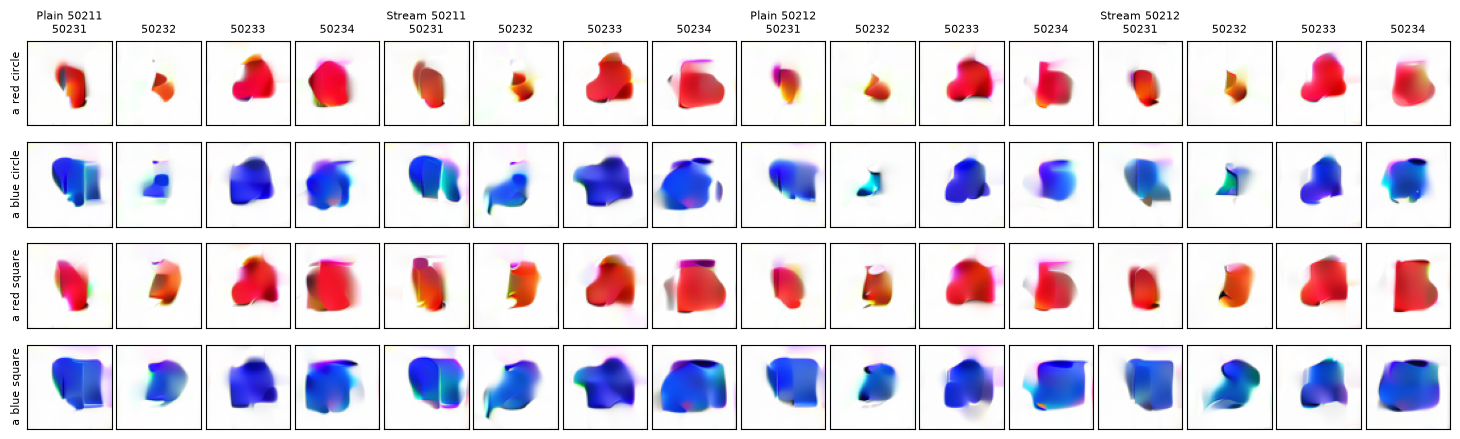

In [7]:
report_scores = prev["report_scores"]
sample_reference = prev["sample_reference"]
val_recon = torch.cat([vae.decode(z) for z in val_z.split(8)])
print("held-out originals:", report_scores(prev["val_x"], val_y))
print("held-out VAE recon:", report_scores(val_recon, val_y))
sample_seeds = (50231, 50232, 50233, 50234)
noise_bank = torch.cat(
    [torch.randn((1, 4, 8, 8), generator=torch.Generator().manual_seed(s)) for s in sample_seeds]
)
starts = noise_bank.repeat((len(captions), 1, 1, 1))
prompt_ids = torch.arange(len(captions)).repeat_interleave(len(sample_seeds))
galleries = {}
for (seed, kind), model in trained.items():
    endpoint, counts = sample_reference(model, starts, prompt_ids, 20, heun=False, scale=1.0)
    assert counts == (20, 20, 20)
    images = torch.cat([vae.decode(z) for z in endpoint.split(8)])
    assert torch.isfinite(images).all()
    galleries[(seed, kind)] = images
    print(f"{seed} {kind:6} | Euler 20 NFE | {report_scores(images, prompt_ids)}")

fig, axes = plt.subplots(4, 16, figsize=(14.7, 4.6))
for j, ((seed, kind), images) in enumerate(galleries.items()):
    for row, caption in enumerate(captions):
        for col, sample_seed in enumerate(sample_seeds):
            ax = axes[row, j * len(sample_seeds) + col]
            img = images[row * len(sample_seeds) + col].permute(1, 2, 0)
            ax.imshow(((img + 1) / 2).clamp(0, 1))
            ax.set_xticks([])
            ax.set_yticks([])
            if row == 0:
                ax.set_title(
                    f"{kind} {seed}\n{sample_seed}" if col == 0 else str(sample_seed), fontsize=8
                )
            if j == 0 and col == 0:
                ax.set_ylabel(caption, fontsize=8)
fig.tight_layout(w_pad=0.35)
plt.show()

### **1. 这次结果应该怎样读**

| 训练种子 | 配置 | 正确条件速度 MSE | 颜色 | 形状 | 同时命中 | 无法解析 |
| --- | --- | --- | --- | --- | --- | --- |
| 50211 | Plain | 0.87247 | 14/16 | 6/16 | 6/16 | 2/16 |
| 50211 | Stream | 0.85246 | 12/16 | 6/16 | 6/16 | 4/16 |
| 50212 | Plain | 0.89049 | 13/16 | 6/16 | 6/16 | 3/16 |
| 50212 | Stream | 0.87049 | 12/16 | 5/16 | 5/16 | 4/16 |

在四组模型上，**错颜色、错形状和空条件都比正确条件误差高**。其中错颜色的代价比错形状明显，和颜色在图库中更易命中的现象一致。速度 MSE 按潜变量元素平均，颜色和形状没有单独的权重。哪一种条件替换引起的误差更大，还会受到数据与潜变量表示影响，不能据此给模型的语义理解强度排序。

Stream 在两次重复中的正确条件 MSE 各低约 0.02，但采样的联合命中一次持平、一次少一张。原图和 VAE 重建均解析到 32/32，生成图中则出现不规则轮廓、形状错配与无法解析。比如在蓝圆行，50232 起始噪声对应的数张结果出现断开的蓝绿色块，颜色接近并没有带来完整圆形。局部速度测量来自固定的留出插值点；实际采样沿模型自身的轨迹前进。误差累计、配置差异和这份小图库的抽样波动都可能影响排序。要回答在正式任务上谁更好，需扩大数据及种子，并另做同主干宽度或同算力比较。

### **2. 规模怎样迁移到正式配置**

这次统计到 Plain 为 609,714 个、Stream 为 645,856 个可训练参数，Stream 多 5.93%。对于本课的无仿射 LayerNorm 和 4 倍 MLP，单个共享 Block 的参数约为 $18d^2+15d$：QKV 与输出投影贡献 $4d^2$，MLP 贡献 $8d^2$，AdaLN 调制贡献 $6d^2$，其余是偏置。计入时间 MLP、输入投影和输出头后才是整网参数；冻结的 VAE 与 CLIP 不计入。

例如 $d=384$、11 层，仅共享 Block 合计约 29.3M。头数还要满足每头可做 2D RoPE，如 8 头时每头 48 维。这个计算可以帮助你选出接近正式约 30M 的起点，最终用真实实例逐项计数，并在目标硬件上记录计算、显存和延迟。

## **七、两段个人练习**

### **1. 先写 Block 的前向，再接 DiT 的数据流**

第一段补 `SingleStreamBlock.forward`：写出调制、QKV 变形、仅图像 Q/K 旋转、键掩码和两个残差。第二段补 `SingleStreamDiT.forward`：处理图文投影、时间条件、可见性、遍历 Block、裁切输出和逆 patch。练习类继承层的构造，仅覆盖你需要亲手写的前向；个人模型明确安装个人 Block。两处 TODO 都留在教学 Notebook，项目模块保持各自的验收边界。

In [8]:
class SingleStreamBlock(SingleStreamBlockReference):
    """个人练习：复用已定义层，填写共享 block 的前向。"""

    def forward(
        self,
        tokens: Tensor,
        time: Tensor,
        valid: Tensor,
        n_text: int,
        coords: Tensor,
    ) -> Tensor:
        raise NotImplementedError("SingleStreamBlock.forward")


class SingleStreamDiT(SingleStreamDiTReference):
    """个人练习：填写投影、拼接、调用 block、输出图像后缀的前向。"""

    block_type = SingleStreamBlock

    def forward(self, z: Tensor, feature_time: Tensor, text: Tensor, text_valid: Tensor) -> Tensor:
        raise NotImplementedError("SingleStreamDiT.forward")

### **2. 写完先跑两个小验收，再尝试从头短训**

第一个检查把注意力残差门主动打开，以手算打分和显式 softmax 对照 SDPA 路线，并检查 padding 特征的梯度。这个小例子将 MLP 门置零，集中定位注意力问题。MLP 与调制接线仍应结合短训和梯度结果检查。第二个换入两层记录调用的替身 Block，逐层注入已知特征变化，检查调用顺序、掩码、坐标、时间和最终反排。单元先验证教学参考，再检查你的前向，尚未实现会显示待完成。前向接口验收通过，再把个人实现明确交给 `velocity`，从随机初始化比较一小段训练曲线。

In [9]:
def check_block(block_type: type[SingleStreamBlockReference]) -> None:
    """激活注意力门，用显式点积验证旋转区间、padding、残差。"""
    block = block_type(width=8, heads=2).double()
    block.norm_a = nn.Identity()
    with torch.no_grad():
        block.modulation[-1].weight.zero_()
        block.modulation[-1].bias.zero_()
        block.modulation[-1].bias[16:24] = 1.0  # g_a = 1，g_m = 0
        block.qkv.weight.copy_(torch.eye(8).repeat(3, 1))
        block.qkv.bias.zero_()
        block.proj.weight.copy_(torch.eye(8))
        block.proj.bias.zero_()
    rng = torch.Generator().manual_seed(50290)
    x = torch.randn((1, 4, 8), generator=rng, dtype=torch.float64).requires_grad_()
    mask = torch.tensor([[True, False, True, True]])
    coords = torch.tensor([[0, 0], [0, 1]])
    raw = x.reshape(1, 4, 2, 4).transpose(1, 2)
    # 只有 (0,1) 的列轴发生旋转，头宽 4 时该轴只有角频率 1 的一对。
    rotated = raw.clone()
    u, v = raw[:, :, 3, 2], raw[:, :, 3, 3]
    rotated[:, :, 3, 2] = u * math.cos(1.0) - v * math.sin(1.0)
    rotated[:, :, 3, 3] = u * math.sin(1.0) + v * math.cos(1.0)
    logits = (rotated @ rotated.transpose(-2, -1)) / 2.0
    expected = x + (logits[..., [0, 2, 3]].softmax(-1) @ raw[:, :, [0, 2, 3]]).transpose(
        1, 2
    ).reshape_as(x)
    expected = torch.where(mask[..., None], expected, 0.0)
    actual = block(x, torch.zeros(1, 8, dtype=x.dtype), mask, 2, coords)
    torch.testing.assert_close(actual, expected, rtol=1e-10, atol=1e-10)
    g = torch.autograd.grad(actual.square().sum(), x)[0]
    assert torch.isfinite(g).all() and torch.count_nonzero(g[~mask]) == 0 and g[mask].norm() > 0


def check_routing(model_type: type[SingleStreamDiTReference]) -> None:
    """用透明探针捕获真实 stream，独立复算图像输出切片。"""
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(50291)
        model = model_type(width=8, heads=2, depth=0, text_width=3).double()
        nn.init.normal_(model.output.weight, std=0.2)

    shift = torch.linspace(-0.2, 0.2, 8, dtype=torch.float64)
    scale = torch.linspace(0.1, 0.3, 8, dtype=torch.float64)
    with torch.no_grad():
        model.final_mod[-1].bias.copy_(torch.cat((shift, scale)))
    update = torch.linspace(0, 0.7, 8, dtype=torch.float64)

    class Trace(nn.Module):
        def forward(
            self,
            tokens: Tensor,
            time: Tensor,
            valid: Tensor,
            n_text: int,
            coords: Tensor,
        ) -> Tensor:
            self.record = (tokens, time, valid, n_text, coords)
            return tokens + update

    first, second = Trace(), Trace()
    model.blocks.extend((first, second))
    z = torch.arange(64, dtype=torch.float64).reshape(1, 4, 4, 4) / 64
    text = torch.tensor([[[0.1, -0.2, 0.3], [9.0, 8.0, 7.0]]], dtype=z.dtype)
    mask = torch.tensor([[True, False]])
    time = torch.tensor([123.0], dtype=z.dtype)
    actual = model(z, time, text, mask)
    tokens, cond, valid, n_text, coords = first.record
    assert tokens.shape == (1, 6, 8) and n_text == 2
    torch.testing.assert_close(valid, torch.tensor([[True, False, True, True, True, True]]))
    torch.testing.assert_close(coords, torch.tensor([[0, 0], [0, 1], [1, 0], [1, 1]]))
    torch.testing.assert_close(cond, model.time_mlp(sincos_1d(time, 8).to(z.dtype)))
    expected_text = (model.text_in(text) + model.modality[0]).masked_fill(~mask[..., None], 0)
    expected_image = model.image_in(patchify(z, 2)) + model.modality[1]
    torch.testing.assert_close(tokens[:, :2], expected_text)
    torch.testing.assert_close(tokens[:, 2:], expected_image)
    torch.testing.assert_close(second.record[0], tokens + update)
    expected_features = model.final_norm(expected_image + 2 * update) * (1 + scale) + shift
    expected = unpatchify(model.output(expected_features), 4, 4, 4, 2)
    torch.testing.assert_close(actual, expected)
    assert actual.shape == z.shape


check_block(SingleStreamBlockReference)
check_routing(SingleStreamDiTReference)
assert isinstance(SingleStreamDiT(depth=1).blocks[0], SingleStreamBlock)
print("教学参考: 显式注意力数值、padding 梯度、两层调用及非零输出反排均通过")

for learner, check in (
    (SingleStreamBlock, check_block),
    (SingleStreamDiT, check_routing),
):
    try:
        check(learner)
    except NotImplementedError as exc:
        if str(exc) != f"{learner.__name__}.forward":
            raise
        print(f"{learner.__name__}.forward: 待完成")
    else:
        print(f"{learner.__name__}.forward: 通过")

教学参考: 显式注意力数值、padding 梯度、两层调用及非零输出反排均通过
SingleStreamBlock.forward: 待完成
SingleStreamDiT.forward: 待完成


## **八、自测与 S6-01 接口**

### **1. 不看代码能解释这些决策吗**

<details>
<summary>问：宽度 120 可以用 4 个注意力头吗？</summary>

一般的多头注意力可以拆成每头 30 维。本课把头宽度平分给行和列，每个子空间还要两两成对旋转，要求每头宽度是 4 的倍数。30 平分得到 15，每轴都无法成对，5 头则得到每头 24 维，每轴 12 维。

</details>

<details>
<summary>问：为什么冻结文本塔，文本却能被图像改变？</summary>

冻结的是生成条件特征的 CLIP 参数。每个去噪步里，主干将这些特征投影成自己的初始文本 Token，联合 Block 会按图像与时间更新它们。下一步可以重用同一份 CLIP 特征，再重新计算主干内的状态。

</details>

<details>
<summary>问：为什么不能根据有效 Token 数裁切？为什么只检验初始速度等于零也不够？</summary>

有效 Token 数取决于提示，拼接边界却取决于填充后的统一槽位数。初始速度被零头截断，错误的裁切或注意力都可能输出同样的零。应分别检查有效边界、主动打开门后的数值结果，以及训练后的非零输出和梯度。

</details>

<details>
<summary>问：正确文本的留出误差更低，能证明生成时必然满足提示吗？</summary>

留出误差测的是已知图像和噪声路径上的局部速度估计。采样从新噪声出发，反复查询自己的中间状态，速度误差可以累积，VAE 解码也影响最终属性。两项证据可以相互解释，需要分别记录。

</details>

### **2. 下一课怎样接 Hybrid**

先沿用本课接口：冻结特征和潜变量作为输入，时间调制，输出同形状的速度。Hybrid 的第一处关键问题是 **哪几层保留各模态自己的投影或子层，何时切换到共享序列**。前半段的模态专用参数与后半段的融合共享要分开计算，过渡处仍保留可见性、坐标与图像后缀约定。这样比较时，训练目标和采样器可以保持同一套。

本课给出了真实的教学前向、短训与采样证据。两段个人练习留待独立完成；正式 B1 的数据、参数规模、训练可靠性和生成能力由工程阶段另行验收。